<a href="https://colab.research.google.com/github/hillarymaximino/hillarymaximino/blob/main/Atividade_Diabetes_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prevendo a progressão do diabetes com Regressão Linear e Redes Neurais Artificiais

**Disciplina:** Inteligência Artificial — IFPB  
**Curso:** Bacharelado em Engenharia de Computação  
**Professor:** Marcelo José Siqueira Coutinho de Almeida  
**Alunos:** Hillary Maximino e Guilherme Gonçalves

## Objetivo

Explorar o conjunto de dados Diabetes, treinar e avaliar uma **Regressão Linear** e uma **Rede Neural Artificial (MLPRegressor)**, comparar os resultados com MAE e RMSE e observar sinais de sobreajuste (*overfitting*) ao variar a arquitetura da rede.


## Etapa 1 — Preparação do ambiente

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

In [ ]:
candidatos_csv = [Path("diabetes.csv"), Path("diabetes(3).csv")]
caminho_csv = next((p for p in candidatos_csv if p.exists()), None)

if caminho_csv is None:
    try:
        from google.colab import files
        arquivos_enviados = files.upload()
        nomes_csv = [nome for nome in arquivos_enviados if nome.lower().endswith(".csv")]
        if not nomes_csv:
            raise FileNotFoundError("Nenhum arquivo CSV foi enviado.")
        caminho_csv = Path(nomes_csv[0])
    except ImportError as erro:
        raise FileNotFoundError(
            "Não encontrei diabetes.csv nem diabetes(3).csv. "
            "Coloque o arquivo CSV na mesma pasta deste notebook."
        ) from erro

print(f"Arquivo utilizado: {caminho_csv}")
dados = pd.read_csv(caminho_csv)

Arquivo utilizado: diabetes(3).csv


In [ ]:
colunas_esperadas = {
    "age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6", "progressao"
}

colunas_faltantes = colunas_esperadas.difference(dados.columns)
if colunas_faltantes:
    raise ValueError(f"Faltam colunas esperadas no CSV: {sorted(colunas_faltantes)}")

if dados[list(colunas_esperadas)].isna().any().any():
    raise ValueError("O conjunto de dados contém valores faltantes; verifique o CSV.")

print(f"Dimensões do conjunto de dados: {dados.shape}")
print(f"Número de pacientes: {dados.shape[0]}")
print(f"Número de atributos preditores: {dados.shape[1] - 1}")
print(f"Total de valores faltantes: {int(dados.isna().sum().sum())}")

Dimensões do conjunto de dados: (442, 11)
Número de pacientes: 442
Número de atributos preditores: 10
Total de valores faltantes: 0


## Etapa 2 — Exploração dos dados

### 2.1 Primeiras linhas, dimensões e estatísticas descritivas

In [ ]:
display(dados.head())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progressao
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [ ]:
print("Dimensões (linhas, colunas):", dados.shape)

Dimensões (linhas, colunas): (442, 11)


In [ ]:
display(dados.describe().round(3))

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progressao
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


### 2.2 Verificação de valores faltantes

In [ ]:
faltantes = dados.isna().sum()
display(faltantes.to_frame("Valores faltantes"))
print("Há valores faltantes?", bool(dados.isna().any().any()))

,Valores faltantes
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Há valores faltantes? False


### 2.3 Correlação de cada atributo com a variável alvo

In [ ]:
correlacoes = dados.corr(numeric_only=True)["progressao"].drop("progressao")
correlacoes_ordenadas = correlacoes.reindex(
    correlacoes.abs().sort_values(ascending=False).index
)
display(correlacoes_ordenadas.to_frame("Correlação com progressao").round(4))

,Correlação com progressao
bmi,0.5865
s5,0.5659
bp,0.4415
s4,0.4305
s3,-0.3948
s6,0.3825
s1,0.2120
age,0.1879
s2,0.1741
sex,0.0431


### 2.4 Gráficos exploratórios

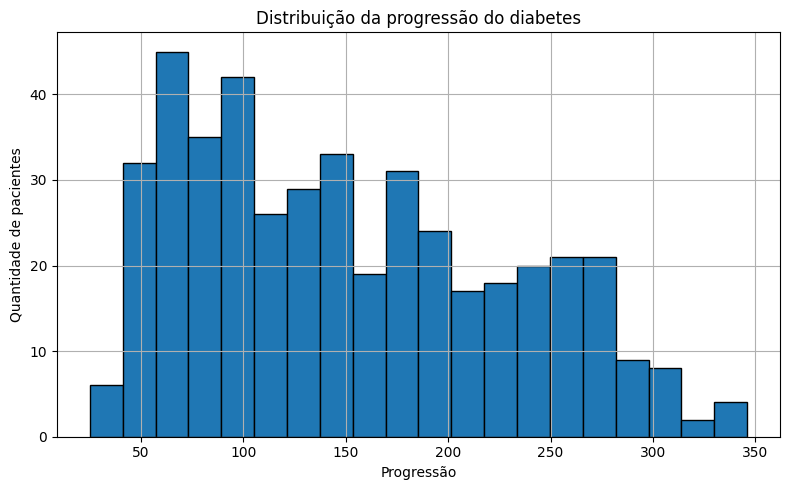

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(dados["progressao"], bins=20, edgecolor="black")
plt.title("Distribuição da progressão do diabetes")
plt.xlabel("Progressão")
plt.ylabel("Quantidade de pacientes")
plt.tight_layout()
plt.show()

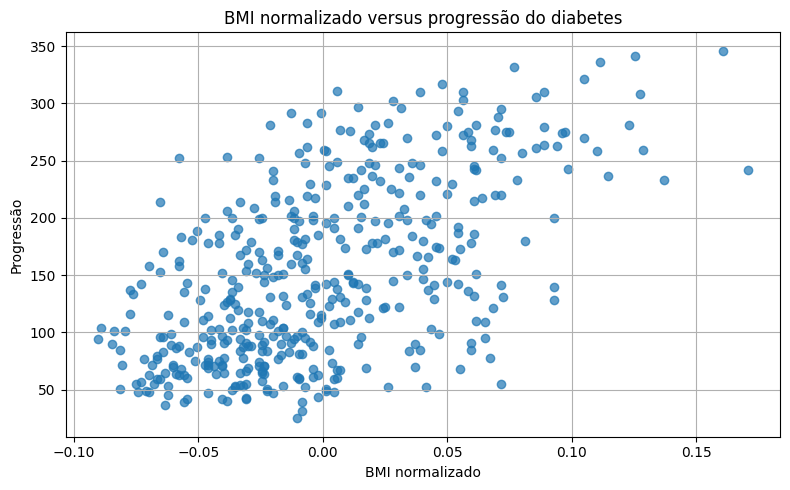

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(dados["bmi"], dados["progressao"], alpha=0.7)
plt.title("BMI normalizado versus progressão do diabetes")
plt.xlabel("BMI normalizado")
plt.ylabel("Progressão")
plt.tight_layout()
plt.show()

### Respostas da Etapa 2

**a) Quais atributos mais se correlacionam com o alvo?**  
Os maiores valores absolutos de correlação são os de `bmi` (aproximadamente **0,5865**) e `s5` (**0,5659**). Depois aparecem `bp` (**0,4415**) e `s4` (**0,4305**). A correlação indica associação linear individual com a variável alvo, não causalidade.

**b) Algum atributo tem correlação negativa?**  
Sim. O atributo `s3` apresenta correlação negativa com `progressao` (aproximadamente **−0,3948**): neste conjunto, valores maiores de `s3` tendem a estar associados a valores menores da variável alvo.

**c) Existe motivo para esperar que um modelo linear resolva bem o problema?**  
A correlação de `bmi` e `s5` sugere que um modelo linear é um ponto de partida razoável. Porém, o diagrama de dispersão mostra que os pontos não ficam exatamente sobre uma reta e os atributos podem estar relacionados entre si. Portanto, espera-se que a regressão linear capture parte da relação, mas não necessariamente toda a variação da progressão.

## Etapa 3 — Divisão em treino e teste

In [ ]:
X = dados.drop(columns=["progressao"])
y = dados["progressao"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Formato de X_treino:", X_treino.shape)
print("Formato de X_teste:", X_teste.shape)
print("Quantidade de registros de treino:", len(y_treino))
print("Quantidade de registros de teste:", len(y_teste))

Formato de X_treino: (353, 10)
Formato de X_teste: (89, 10)
Quantidade de registros de treino: 353
Quantidade de registros de teste: 89


### Resposta da Etapa 3

A avaliação final deve ser feita no conjunto de teste porque ele representa dados que não foram usados para ajustar o modelo. Assim, as métricas dão uma estimativa mais justa de como o modelo pode se comportar em dados novos. Se usássemos os mesmos dados para treinar e avaliar, o desempenho poderia parecer artificialmente melhor.

## Etapa 4 — Modelo 1: Regressão Linear

In [ ]:
modelo_linear = LinearRegression()
modelo_linear.fit(X_treino, y_treino)
previsoes_linear = modelo_linear.predict(X_teste)

mae_linear = mean_absolute_error(y_teste, previsoes_linear)
rmse_linear = np.sqrt(mean_squared_error(y_teste, previsoes_linear))

print(f"MAE da Regressão Linear no teste: {mae_linear:.2f}")
print(f"RMSE da Regressão Linear no teste: {rmse_linear:.2f}")

MAE da Regressão Linear no teste: 42.79
RMSE da Regressão Linear no teste: 53.85


### 4.1 Coeficientes do modelo

In [ ]:
coeficientes = pd.Series(modelo_linear.coef_, index=X.columns, name="Coeficiente")
coeficientes_ordenados = coeficientes.reindex(
    coeficientes.abs().sort_values(ascending=False).index
)
display(coeficientes_ordenados.to_frame().round(2))

,Coeficiente
s1,-931.49
s5,736.20
bmi,542.43
s2,518.06
bp,347.70
s4,275.32
sex,-241.96
s3,163.42
s6,48.67
age,37.90


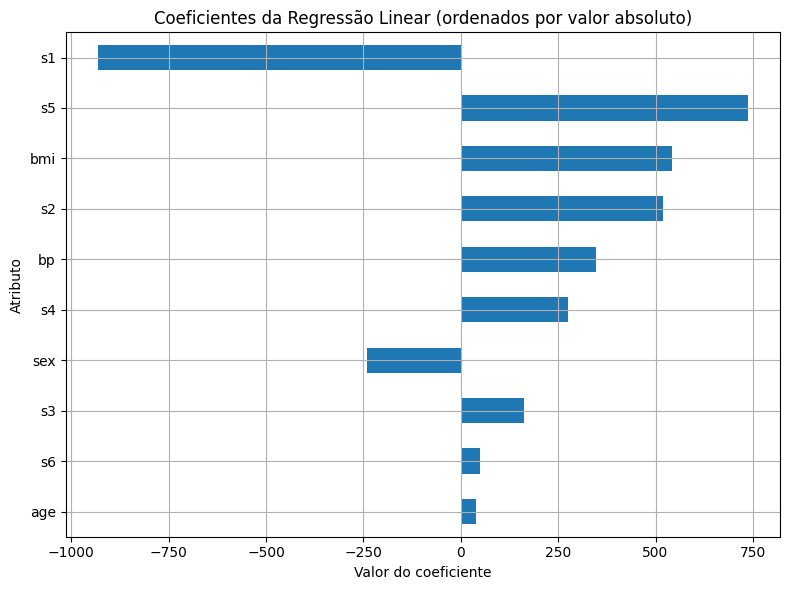

In [ ]:
ordem = coeficientes.abs().sort_values().index
plt.figure(figsize=(8, 6))
coeficientes.loc[ordem].plot(kind="barh")
plt.title("Coeficientes da Regressão Linear (ordenados por valor absoluto)")
plt.xlabel("Valor do coeficiente")
plt.ylabel("Atributo")
plt.tight_layout()
plt.show()

### 4.2 Valores previstos versus valores reais

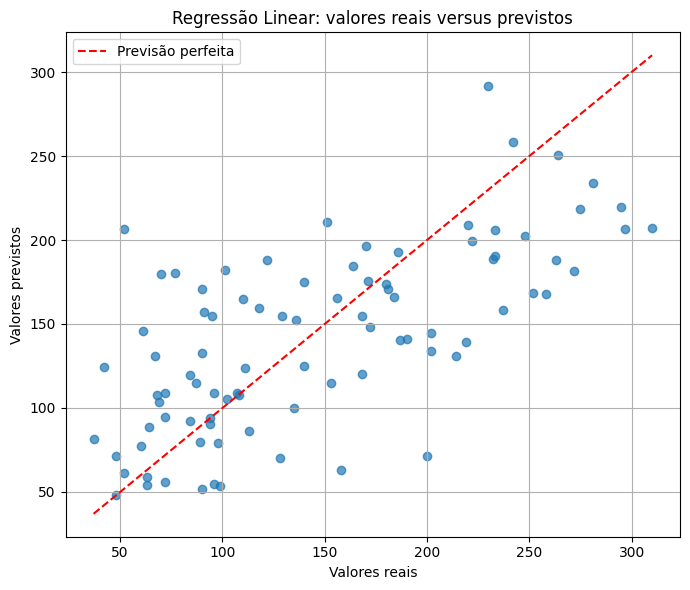

In [ ]:
minimo_linear = min(y_teste.min(), previsoes_linear.min())
maximo_linear = max(y_teste.max(), previsoes_linear.max())

plt.figure(figsize=(7, 6))
plt.scatter(y_teste, previsoes_linear, alpha=0.7)
plt.plot(
    [minimo_linear, maximo_linear],
    [minimo_linear, maximo_linear],
    "r--",
    label="Previsão perfeita"
)
plt.title("Regressão Linear: valores reais versus previstos")
plt.xlabel("Valores reais")
plt.ylabel("Valores previstos")
plt.legend()
plt.tight_layout()
plt.show()

### Respostas da Etapa 4

**a) Quais atributos têm os maiores coeficientes em valor absoluto?**  
Nesta divisão treino/teste, os maiores são `s1` (aproximadamente **−931,49**), `s5` (**736,20**), `bmi` (**542,43**) e `s2` (**518,06**).

**b) Esses coeficientes coincidem com as correlações da Etapa 2? Por que podem divergir?**  
Não necessariamente. A correlação da Etapa 2 analisa cada atributo isoladamente; já o coeficiente da regressão múltipla representa a contribuição estimada de um atributo considerando os demais atributos do modelo. Como `s1`, `s2` e `s3` medem grandezas relacionadas, podem compartilhar informação. Essa relação entre preditores pode alterar a magnitude e até o sinal dos coeficientes. Além disso, os atributos foram normalizados e a variável alvo não, então os coeficientes não representam unidades clínicas originais.

## Etapa 5 — Modelo 2: Rede Neural Artificial (RNA)

### 5.1 Arquitetura principal: duas camadas ocultas (16 e 8 neurônios)

In [ ]:
modelo_rna = MLPRegressor(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=20000,
    random_state=42
)

modelo_rna.fit(X_treino, y_treino)
previsoes_rna = modelo_rna.predict(X_teste)

mae_rna = mean_absolute_error(y_teste, previsoes_rna)
rmse_rna = np.sqrt(mean_squared_error(y_teste, previsoes_rna))

print(f"Iterações realizadas: {modelo_rna.n_iter_}")
print(f"MAE da RNA (16, 8) no teste: {mae_rna:.2f}")
print(f"RMSE da RNA (16, 8) no teste: {rmse_rna:.2f}")

Iterações realizadas: 3441
MAE da RNA (16, 8) no teste: 42.76
RMSE da RNA (16, 8) no teste: 53.73


### 5.2 Experimento: comparação de arquiteturas

As arquiteturas abaixo seguem os exemplos sugeridos no roteiro. Para cada uma são registrados MAE e RMSE no treino e no teste. O limite de iterações foi aumentado para permitir a convergência da arquitetura pequena `(4,)`; a coluna de iterações ajuda a interpretar o treinamento.

In [ ]:
arquiteturas = [
    (4,),
    (16,),
    (16, 8),
    (64, 32),
    (128, 64, 32)
]

resultados_arquiteturas = []

for arquitetura in arquiteturas:
    modelo = MLPRegressor(
        hidden_layer_sizes=arquitetura,
        activation="relu",
        solver="adam",
        max_iter=20000,
        random_state=42
    )

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_treino, y_treino)

    previsoes_treino = modelo.predict(X_treino)
    previsoes_teste = modelo.predict(X_teste)
    convergiu = not any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos)

    resultados_arquiteturas.append({
        "Arquitetura": str(arquitetura),
        "MAE treino": mean_absolute_error(y_treino, previsoes_treino),
        "RMSE treino": np.sqrt(mean_squared_error(y_treino, previsoes_treino)),
        "MAE teste": mean_absolute_error(y_teste, previsoes_teste),
        "RMSE teste": np.sqrt(mean_squared_error(y_teste, previsoes_teste)),
        "Iterações": modelo.n_iter_,
        "Convergiu": convergiu
    })

tabela_arquiteturas = pd.DataFrame(resultados_arquiteturas)
display(tabela_arquiteturas.round(2))

,Arquitetura,MAE treino,RMSE treino,MAE teste,RMSE teste,Iterações,Convergiu
0,"(4,)",43.67,53.83,42.82,53.73,15617,True
1,"(16,)",43.61,53.82,42.80,53.77,8690,True
2,"(16, 8)",43.66,53.85,42.76,53.73,3441,True
3,"(64, 32)",43.65,53.85,42.81,53.79,1633,True
4,"(128, 64, 32)",20.35,29.76,53.49,68.74,6185,True


### Interpretação do experimento de arquiteturas

Compare os erros de treino com os de teste. Quando uma arquitetura apresenta erro muito menor no treino, mas erro maior no teste, isso indica que ela pode estar memorizando particularidades dos dados de treino e generalizando pior.

Neste conjunto e com a divisão fixa utilizada, a arquitetura `(128, 64, 32)` apresenta um erro de treino consideravelmente menor do que o erro de teste. Esse padrão é um sinal de **overfitting (sobreajuste)**. Uma arquitetura mais complexa não garante melhor desempenho em dados que não participaram do treinamento.

## Etapa 6 — Comparação dos modelos

### 6.1 Tabela comparativa: métricas no conjunto de teste

In [ ]:
tabela_comparativa = pd.DataFrame({
    "Modelo": ["Regressão Linear", "RNA (16, 8)"],
    "MAE teste": [mae_linear, mae_rna],
    "RMSE teste": [rmse_linear, rmse_rna]
})

display(tabela_comparativa.round(2))
print(f"Diferença absoluta de MAE (Linear − RNA): {abs(mae_linear - mae_rna):.2f}")
print(f"Diferença absoluta de RMSE (Linear − RNA): {abs(rmse_linear - rmse_rna):.2f}")

,Modelo,MAE teste,RMSE teste
0,Regressão Linear,42.79,53.85
1,"RNA (16, 8)",42.76,53.73


Diferença absoluta de MAE (Linear − RNA): 0.04
Diferença absoluta de RMSE (Linear − RNA): 0.13


### 6.2 Gráficos lado a lado: valores previstos versus reais

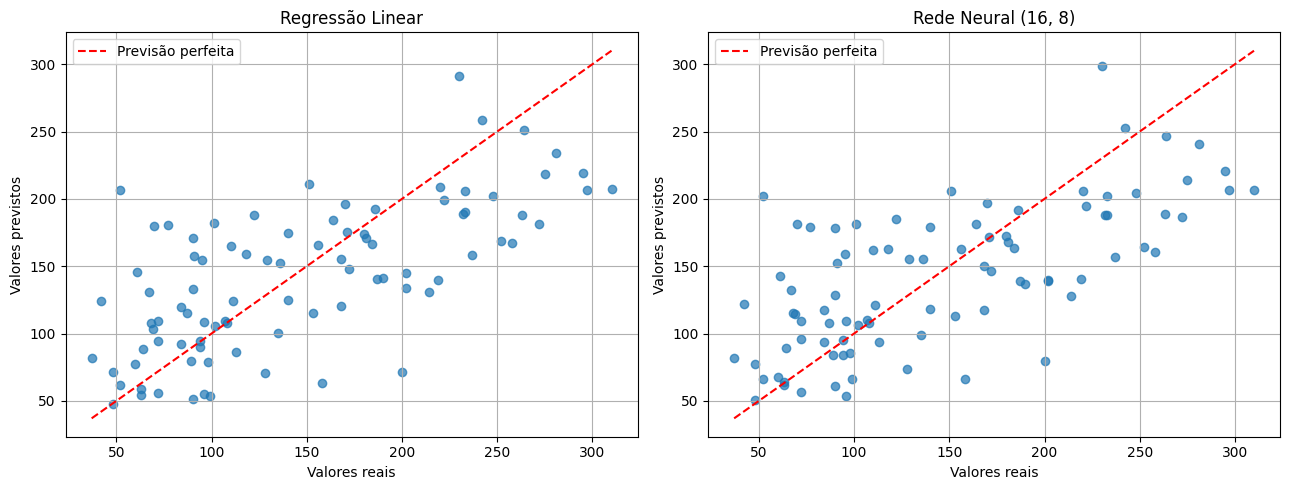

In [ ]:
minimo = min(y_teste.min(), previsoes_linear.min(), previsoes_rna.min())
maximo = max(y_teste.max(), previsoes_linear.max(), previsoes_rna.max())

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))

eixos[0].scatter(y_teste, previsoes_linear, alpha=0.7)
eixos[0].plot([minimo, maximo], [minimo, maximo], "r--", label="Previsão perfeita")
eixos[0].set_title("Regressão Linear")
eixos[0].set_xlabel("Valores reais")
eixos[0].set_ylabel("Valores previstos")
eixos[0].legend()

eixos[1].scatter(y_teste, previsoes_rna, alpha=0.7)
eixos[1].plot([minimo, maximo], [minimo, maximo], "r--", label="Previsão perfeita")
eixos[1].set_title("Rede Neural (16, 8)")
eixos[1].set_xlabel("Valores reais")
eixos[1].set_ylabel("Valores previstos")
eixos[1].legend()

plt.tight_layout()
plt.show()

### 6.3 Em quais faixas do alvo os modelos erram mais?

In [ ]:
analise_erros = pd.DataFrame({
    "real": y_teste.to_numpy(),
    "prev_linear": previsoes_linear,
    "prev_rna": previsoes_rna
})

analise_erros["erro_linear"] = (analise_erros["real"] - analise_erros["prev_linear"]).abs()
analise_erros["erro_rna"] = (analise_erros["real"] - analise_erros["prev_rna"]).abs()

faixas = [0, 100, 150, 200, 250, float("inf")]
nomes_faixas = ["Até 100", "101–150", "151–200", "201–250", "Acima de 250"]

analise_erros["faixa"] = pd.cut(
    analise_erros["real"],
    bins=faixas,
    labels=nomes_faixas,
    include_lowest=True
)

resumo_faixas = analise_erros.groupby("faixa", observed=False).agg(
    Quantidade=("real", "size"),
    MAE_Linear=("erro_linear", "mean"),
    MAE_RNA=("erro_rna", "mean")
)
display(resumo_faixas.round(2))

faixa_maior_erro_linear = resumo_faixas["MAE_Linear"].idxmax()
faixa_maior_erro_rna = resumo_faixas["MAE_RNA"].idxmax()
print(f"Faixa de maior MAE da Regressão Linear: {faixa_maior_erro_linear}")
print(f"Faixa de maior MAE da RNA: {faixa_maior_erro_rna}")

,Quantidade,MAE_Linear,MAE_RNA
faixa,,,
Até 100,34,40.35,39.61
101–150,15,31.56,31.60
151–200,17,35.46,35.27
201–250,13,48.93,50.28
Acima de 250,10,72.43,73.12


Faixa de maior MAE da Regressão Linear: Acima de 250
Faixa de maior MAE da RNA: Acima de 250


### Respostas da Etapa 6

A tabela comparativa permite avaliar ambos os modelos usando exatamente o mesmo conjunto de teste. Quanto menores o MAE e o RMSE, melhor. Os gráficos devem ser lidos em relação à reta identidade: quanto mais próximos os pontos estiverem dela, mais próximas estão as previsões dos valores reais.

A tabela por faixas calcula o MAE separadamente para cada intervalo da variável alvo. Na divisão usada, a faixa **acima de 250** é a que apresenta o maior erro médio absoluto para os dois modelos. Isso sugere maior dificuldade para prever progressões elevadas. Como há menos observações nessas faixas, esses resultados devem ser interpretados com cuidado.

## Etapa 7 — Discussão e conclusões

**1. Qual modelo obteve o melhor desempenho no conjunto de teste? A diferença é relevante?**  
Com a divisão definida por `random_state=42`, a RNA com arquitetura `(16, 8)` apresenta MAE de aproximadamente **42,76** e RMSE de **53,73**; a Regressão Linear apresenta MAE de aproximadamente **42,79** e RMSE de **53,85**. A RNA tem os valores ligeiramente menores, mas a diferença é muito pequena. Portanto, não há evidência de uma melhoria prática importante apenas com essa comparação.

**2. Considerando complexidade, custo de treinamento e interpretabilidade, qual modelo você escolheria?**  
Eu escolheria a **Regressão Linear** como modelo inicial para este problema. Seu desempenho de teste é praticamente igual ao da RNA `(16, 8)`, enquanto seu treinamento é mais simples e seus coeficientes permitem uma interpretação mais direta. A RNA pode representar relações mais complexas, mas neste experimento não trouxe uma vantagem relevante que compense a complexidade extra.

**3. Se o experimento fosse repetido com outra divisão treino/teste, os mesmos valores seriam esperados? Por quê?**  
Não necessariamente. Outra divisão colocaria pacientes diferentes nos conjuntos de treino e teste, mudando os dados usados para ajustar e avaliar os modelos e, consequentemente, as métricas. O parâmetro `random_state=42` torna esta divisão reproduzível; mantendo os dados, o código e as configurações, a execução pode ser repetida para conferir os mesmos resultados.

### Conclusão geral

A atividade mostra que a Regressão Linear é uma referência competitiva para este conjunto de dados. A RNA `(16, 8)` apresentou métricas semelhantes, enquanto a arquitetura mais complexa `(128, 64, 32)` mostrou um padrão de sobreajuste, com erro de treino bem menor e erro de teste maior. Assim, aumentar o número de neurônios e camadas não garante melhor generalização. A escolha do modelo deve considerar as métricas em dados não vistos, a complexidade e a facilidade de interpretação.